# Modelo 5.1 — ablação do número da porta

Experimento isolado: comparar Random Forest com e sem `num_porta`, usando as mesmas linhas, datas, hiperparâmetros e semente. O modelo candidato exclui `num_porta` antes do treinamento e da seleção de atributos.

`id_porta` continua disponível apenas para junções e avaliação por evento. `est_cod` e `via_cod` são mantidos para isolar o efeito de uma única remoção. Esta avaliação temporal não comprova generalização para portas/estações inéditas.

Execute todas as células a partir da raiz do repositório ou desta pasta. Os resultados e o artefato experimental ficam em `artefatos/modelo_5_1/`; nenhum modelo do serviço é substituído.

## 1. Como a tabela foi montada

A junção das quatro bases já tratadas na Sprint 1 (Alarmes, ZM01, ZM02, ZM03) foi feita no arquivo `construir_painel.py`, que gera `painel.parquet`.

Resumo do que o script fez:

- O que foi analisado: 480 portas individuais em 10 estações, durante 2 anos de histórico (gerando cerca de 307 mil registros de porta por dia).
- Como os dados foram cruzados: Usou-se um código padrão (Estação + Via + Número da Porta) extraído via texto das duas bases de dados.
- O foco principal: O alarme da porta (PDM), que é a peça que falha e gera ordem de manutenção, e não o painel central (MDU).
- A meta do modelo: Prever se uma porta específica vai precisar de manutenção corretiva (ordem ZM01) nos próximos 1 a 7 dias.
- Cuidados tomados: Nenhuma informação do próprio dia ou do futuro foi usada para criar os indicadores, garantindo que o modelo aprenda com o passado real (a taxa média de falhas identificada foi de 8,09%).




## 2. Features candidatas e por que cada grupo faz sentido

Aqui foi pensado as melhores features para o modelo encontrar uma falha.

| Grupo | Exemplos | Por que faz sentido |
|---|---|---|
| Alarmes por tipo, janela móvel (1/3/7/14/30d) | `n_LSD_7d`, `n_FC_30d`, `n_CA_14d`... | Cada tipo de alarme marca um sintoma diferente de desgaste; janelas diferentes mostram se o problema é recente ou crônico. |
| Duração do alarme | `dur_max_7d`, `dur_max_30d` | Alarme que demora mais pra normalizar geralmente indica defeito mais sério que um pico rápido. |
| Recência | `n_total_decaido_h7`, `n_LSD_decaido_h7` | Alarme de ontem pesa mais que alarme de 3 semanas atrás — o problema tende a se agravar com o tempo. |
| Alarme do módulo de plataforma | `n_mdu_7d` | Sinal auxiliar: não é da porta em si, mas pode indicar problema compartilhado entre portas da mesma via. |
| Histórico SAP | `dias_desde_zm01`, `zm01_90d`, `zm02_30d`, `zm03_90d` | Porta que já teve correção recente ou recorrente tende a voltar a falhar. |
| Localização | `est_cod`, `via_cod` | Mantidas para isolar a remoção de `num_porta`; generalização ainda precisa ser validada. |
| Ablação | `num_porta` | Usada somente no controle; excluída dos candidatos 5.1. |

### Features criadas

Além das colunas acima, foi combinado algumas delas pra resumir um padrão que não aparece bem numa coluna isolada:

- Mudança recente (rampa_7d): Mostra se os alarmes estão acelerando na última semana em comparação com a semana anterior.
- Comportamento fora do comum (razao_7d_30d): Identifica se a porta está falhando mais do que o seu padrão normal do último mês (destaca portas "calmas" que começaram a dar problema).
- Filtro de alarmes reais (frac_tecnicos_30d): Separa as falhas OBS mecânica/técnica real de simples observações ou ruídos sem defeito.
- Localização (est_cod / via_cod): Códigos numéricos para o modelo saber em qual estação e via a porta está localizada.

### Features de ciclo/recorrência

Uma ideia implementada que parecia fazer sentido testar é: quanto tempo faz desde a última corretiva, e com que frequência aquela porta costuma quebrar. A intuição é a de desgaste por ciclo. Depois de um concerto, a porta vai durar um tempo antes de quebrar de novo

- **dias_desde_ultima_corretiva**: dias desde a última ZM01 ou ZM02, o que for mais recente.
- **n_corretivas_historico_total**: quantas corretivas essa porta já teve até aquele dia.
- **intervalo_medio_zm01**: intervalo médio, até aquele dia, entre as corretivas ZM01 daquela porta, o ritmo normal de quebra dela.
- **razao_atraso_zm01**: dias_desde_zm01 / intervalo_medio_zm01. Então acima de 1 significa que a porta já está atrasada em relação ao próprio ciclo.

### Duas decisões de exclusão

- **Horário de pico** Não entrou, porque o modelo esta analisando uma semana inteira, e não um dia.
- **Normalização (StandardScaler)** Não foi necessário porque o modelo de Random Forest decide por cortes de valor em cada feature, então a escala da coluna não influencia o modelo (mais detalhe na seção 4).

In [1]:
import re
import pandas as pd, numpy as np

from pathlib import Path

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'models/modelo-5/painel.parquet').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Execute dentro do repositório que contém models/modelo-5/painel.parquet')
OUT = ROOT / 'models/modelo-5/artefatos/modelo_5_1'
OUT.mkdir(parents=True, exist_ok=True)
painel = pd.read_parquet(ROOT / 'models/modelo-5/painel.parquet')

# recarrega as ordens ZM01 (mesma regex de construir_painel.py) so para montar
# as features de ciclo/recorrencia abaixo -- nao repete o parsing do restante do painel
PAT_LOC = re.compile(r'^SP04-6-PSD-([A-Z]{3})(?:-PLT(\d)|-P(\d)S\d)?(?:-PP(\d{2})(PDM|PFX|PSE))?')


def carrega_ordens(caminho, aba):
    df = pd.read_excel(caminho, aba)
    m = df['local_de_instalacao'].apply(lambda s: PAT_LOC.match(s) if isinstance(s, str) else None)
    df['est'] = [x.group(1) if x else None for x in m]
    df['via'] = [(x.group(2) or x.group(3)) if x else None for x in m]
    df['porta'] = [int(x.group(4)) if x and x.group(4) else None for x in m]
    df = df.dropna(subset=['est', 'via', 'porta', 'inicio_avaria_datetime']).copy()
    df['porta'] = df['porta'].astype(int)
    df['id_porta'] = df['est'] + '_' + df['via'] + '_' + df['porta'].astype(str).str.zfill(2)
    df['Data'] = pd.to_datetime(df['inicio_avaria_datetime']).dt.normalize()
    return df


zm01 = carrega_ordens(ROOT / 'data/Corretiva Emergencial/processados/ZM01_limpa.xlsx', 'ZM01_limpa')

# contagem historica total e intervalo medio entre corretivas -- causal (so eventos < t)
ev = zm01[['id_porta', 'Data']].dropna().drop_duplicates().sort_values(['id_porta', 'Data']).reset_index(drop=True)
ev['ordem'] = ev.groupby('id_porta').cumcount() + 1
ev['diff'] = ev.groupby('id_porta')['Data'].diff().dt.days
ev['intervalo_medio_ate_aqui'] = ev.groupby('id_porta')['diff'] \
    .apply(lambda s: s.expanding().mean()).reset_index(level=0, drop=True)

p = painel[['id_porta', 'Data']].copy()
p['_idx'] = painel.index  # merge_asof descarta o indice; ele viaja como coluna
m = pd.merge_asof(p.sort_values('Data'),
                   ev[['id_porta', 'Data', 'ordem', 'intervalo_medio_ate_aqui']].sort_values('Data'),
                   on='Data', by='id_porta', direction='backward', allow_exact_matches=False)
painel['n_corretivas_historico_total'] = pd.Series(m['ordem'].values, index=m['_idx'].values) \
    .reindex(painel.index).fillna(0)
_interv = pd.Series(m['intervalo_medio_ate_aqui'].values, index=m['_idx'].values).reindex(painel.index)
# Imputação fixa e causal: não estima a mediana usando o período de teste.
painel['intervalo_medio_zm01'] = _interv.fillna(30.0)
painel['razao_atraso_zm01'] = painel['dias_desde_zm01'] / painel['intervalo_medio_zm01']
painel['dias_desde_ultima_corretiva'] = painel[['dias_desde_zm01', 'dias_desde_zm02']].min(axis=1)

cols_ciclo = ['dias_desde_ultima_corretiva', 'n_corretivas_historico_total',
              'intervalo_medio_zm01', 'razao_atraso_zm01']
print(painel[cols_ciclo].describe().round(1).T.to_string())

                                 count   mean     std  min   25%   50%    75%     max
dias_desde_ultima_corretiva   306864.0  310.3  1406.3  1.0  25.0  65.0  150.0  9999.0
n_corretivas_historico_total  306864.0    8.0     6.7  0.0   3.0   6.0   11.0    57.0
intervalo_medio_zm01          306864.0   82.1    77.7  1.0  35.4  59.4   96.0   886.0
razao_atraso_zm01             306864.0   16.1    65.2  0.0   0.4   1.0    2.8   333.3


In [2]:
# features derivadas ja existentes (ver justificativa na secao anterior)
painel['rampa_7d'] = painel['n_total_7d'] - (painel['n_total_14d'] - painel['n_total_7d'])
painel['razao_7d_30d'] = painel['n_total_7d'] / (painel['n_total_30d'] / 4 + 1)
painel['frac_tecnicos_30d'] = painel['n_tecnicos_30d'] / (painel['n_total_30d'] + 1)
painel['est_cod'] = painel['est'].astype('category').cat.codes
painel['via_cod'] = painel['via'].astype(int)

EXCLUI = {'id_porta', 'Data', 'est', 'via', 'id_plat', 'y', 'n_falhas_7d_futuro', 'cobertura_30d', 'mes'}
FEATS_CONTROLE = [c for c in painel.columns if c not in EXCLUI]
FEATS = [c for c in FEATS_CONTROLE if c != 'num_porta']
assert 'num_porta' in FEATS_CONTROLE
assert set(FEATS_CONTROLE) - set(FEATS) == {'num_porta'}
assert not {'num_porta', 'id_porta', 'id_plat'} & set(FEATS)
print(f'Controle: {len(FEATS_CONTROLE)} atributos | candidato 5.1: {len(FEATS)} atributos')

Controle: 83 atributos | candidato 5.1: 82 atributos


## 3. Separação treino/teste

Normalmente a divisão de dados para treino e teste seria 80/20%, porém aqui, a divisão entre treino e teste foi feita por data (passado vs. futuro), e não aleatoriamente, para simular o uso do modelo na vida real e evitar o vazamento de dados. O motivo do porque não dividir ao acaso foi que, como os dados usam médias dos últimos 30 dias, dias vizinhos são quase idênticos. Misturar eles faria o modelo "decorar" o teste, criando uma falsa sensação de alta precisão.

Divisão temporal: O modelo treina com o passado e é testado no futuro.

Margem de segurança (folga de 7 dias): Foi deixado um intervalo de 7 dias entre o treino e o teste para garantir que nenhuma informação da janela de previsão se cruze entre as duas etapas.

Ajuste de alertas (limiar): A sensibilidade para emitir alertas é configurada usando apenas os dados de treino, sem olhar os resultados do teste.


In [3]:
FIM_TREINO, INI_TESTE, INI_VALID = (pd.Timestamp('2025-04-23'), pd.Timestamp('2025-05-01'),
                                          pd.Timestamp('2025-01-31'))
treino = painel[painel['Data'] <= FIM_TREINO]
teste = painel[painel['Data'] >= INI_TESTE]
tr_fit = treino[treino['Data'] <= INI_VALID - pd.Timedelta(days=8)]
tr_val = treino[treino['Data'] >= INI_VALID]

print(f'treino: {len(treino):,} linhas | teste: {len(teste):,} linhas')
print(f'taxa de falha treino: {treino["y"].mean()*100:.2f}% | teste: {teste["y"].mean()*100:.2f}%')
assert treino['Data'].max() + pd.Timedelta(days=7) < teste['Data'].min()
assert tr_fit['Data'].max() + pd.Timedelta(days=7) < tr_val['Data'].min()
assert all(not frame.empty and frame['y'].nunique() == 2
           for frame in (tr_fit, tr_val, treino, teste))

treino: 232,992 linhas | teste: 71,184 linhas
taxa de falha treino: 7.90% | teste: 8.71%


## 4. Como o Random Forest funciona

O Random Forest é um algoritmo de aprendizado de máquina supervisionado que combina as previsões de múltiplas árvores de decisão para gerar um resultado final mais preciso e estável, funcionando tanto para classificação quanto para regressão.
Ele lida com o problema de overfitting criando diversidade entre as árvores através de dois mecanismos:

- Seleção de dados: Cada árvore é treinada com uma amostra aleatória das linhas do conjunto original.
- Seleção de variáveis: Em cada divisão da árvore, apenas um subconjunto aleatório das colunas é considerado.


Pra esse problema, o Random Forest foi escolhido por três motivos práticos:
- Ele lida bem com combinações de sinais sem precisar criar a combinação manualmente;
- Não precisa normalizar os dados;
- Combina bem com SHAP (o TreeExplainer é exato e rápido pra árvores), o que permite abrir a caixa-preta na próxima seção.

### Parâmetros escolhidos

- n_estimators=400: número de árvores no forest. 400 é o suficiente pra média das previsões
  ficar estável (o modelo para de melhorar significativamente depois desse numero).
- max_depth=14: limita quão fundo cada árvore pode crescer. Sem esse limite, a árvore cresceria
  até decorar cada linha do treino; com ~300 mil linhas isso ia gerar uma árvore muito grande e sobreajustada.
- min_samples_leaf=40: cada folha da árvore precisa ter pelo menos 40 linhas por trás dela.
  Isoo faz com que o modelo crie regras baseadas em pouco casos, isso é importante porque
  falha é um evento raro, então é fácil encontrar um padrão em algumas linhas que
  na verdade é só ruído.
- random_state=42: fixa a aleatoriedade (amostragem de linhas e de features de cada árvore) pra
  o resultado ser reprodutível.


### Busca de hiperparâmetros

Os parâmetros até aqui foram escolhidos manualmente, com base no que fazia sentido pro problema, eles não vieram de uma busca automatizada. Foi pensado para um próximo passo, testar um `RandomizedSearchCV`, para tentar achar hiperparametros diferentes (`n_estimators`, `max_depth`, `min_samples_leaf`) e ver se o modelo performa melhor.

Porém foi descoberto que, o RandomizedSearchCV (assim como o `GridSearchCV`) precisa validar cada combinação de parâmetros em algum recorte dos dados antes de decidir qual é a melhor. Por padrão essa validação usa K-Fold aleatório, que embaralha as linhas. Entretanto isso leva ao mesmo problema da seção 3, porque as features de janela móvel fariam dias vizinhos vazarem informação entre treino e validação dentro da busca.

Por isso a busca vai utilizar `TimeSeriesSplit` como cv. No lugar de embaralhar, o TimeSeriesSplit corta o treino em pedaços sequenciais, sempre validando num período que vem depois do treino daquele fold, sem tocar no teste real.

Depois do RandomizedSearchCV (mais rápido, testando um número escolhido de combinações), o plano é rodar um GridSearchCV perto do melhor resultado encontrado, pra comparar se a busca mais completa muda algo ou só confirma o que o random search já achou.

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, roc_auc_score, confusion_matrix)


def melhor_limiar(y, prob):
    grid = np.unique(np.quantile(prob, np.linspace(0.50, 0.999, 200)))
    return max(((f1_score(y, (prob >= t).astype(int), zero_division=0), t) for t in grid))[1]


def avalia(nome, yte, pred, prob):
    tn, fp, fn, tp = confusion_matrix(yte, pred, labels=[0, 1]).ravel()
    return {'modelo': nome, 'precisao': precision_score(yte, pred, zero_division=0),
            'recall': recall_score(yte, pred, zero_division=0), 'f1': f1_score(yte, pred, zero_division=0),
            'pr_auc': average_precision_score(yte, prob), 'roc_auc': roc_auc_score(yte, prob),
            'alertas': int(pred.sum()), 'tp': int(tp), 'fp': int(fp), 'fn': int(fn)}


def treina_avalia(feats, tag):
    Xtr, ytr, Xte, yte = treino[feats], treino['y'], teste[feats], teste['y']
    mod = RandomForestClassifier(n_estimators=400, max_depth=14, min_samples_leaf=40,
                                  class_weight='balanced', n_jobs=-1, random_state=42)
    mod.fit(tr_fit[feats], tr_fit['y'])
    lim = melhor_limiar(tr_val['y'], mod.predict_proba(tr_val[feats])[:, 1])
    mod.fit(Xtr, ytr)
    prob = mod.predict_proba(Xte)[:, 1]
    pred = (prob >= lim).astype(int)
    linha = avalia(tag, yte, pred, prob)
    linha.update(limiar=float(lim), n_features=len(feats))
    print(f'[{tag}] limiar={lim:.4f}')
    print(pd.DataFrame([linha]).round(3).to_string(index=False))
    return mod, prob, lim, linha


mod_controle, prob_controle, lim_controle, linha_controle = treina_avalia(
    FEATS_CONTROLE, 'Controle com num_porta')
mod_full, prob_full, lim_full, linha_full = treina_avalia(
    FEATS, '5.1 sem num_porta (ablação direta)')
assert 'num_porta' not in mod_full.feature_names_in_
comparacao_ablacao = pd.DataFrame([linha_controle, linha_full])
comparacao_ablacao.to_csv(OUT / 'comparacao_ablacao.csv', index=False)
print(comparacao_ablacao.round(4).to_string(index=False))

[Controle com num_porta] limiar=0.5260
                modelo  precisao  recall    f1  pr_auc  roc_auc  alertas   tp    fp   fn  limiar  n_features
Controle com num_porta     0.161   0.533 0.247   0.185    0.696    20513 3303 17210 2899   0.526          83
[5.1 sem num_porta (ablação direta)] limiar=0.5169
                            modelo  precisao  recall    f1  pr_auc  roc_auc  alertas   tp    fp   fn  limiar  n_features
5.1 sem num_porta (ablação direta)     0.156   0.572 0.245   0.184    0.696    22815 3550 19265 2652   0.517          82
                            modelo  precisao  recall     f1  pr_auc  roc_auc  alertas   tp    fp   fn  limiar  n_features
            Controle com num_porta    0.1610  0.5326 0.2473  0.1849   0.6962    20513 3303 17210 2899  0.5260          83
5.1 sem num_porta (ablação direta)    0.1556  0.5724 0.2447  0.1839   0.6955    22815 3550 19265 2652  0.5169          82


## 5. Interpretando o candidato sem número da porta

A seleção SHAP usa somente uma amostra do treino, nunca o teste final. A amostra de 400 linhas e semente 42 limita o custo deste experimento. A comparação principal da ablação é a seção anterior, antes da seleção: a única diferença entre seus conjuntos de atributos é `num_porta`.

In [5]:
import shap

amostra = treino.sample(n=min(400, len(treino)), random_state=42)
explainer = shap.TreeExplainer(mod_full)
sv = explainer.shap_values(amostra[FEATS])
if isinstance(sv, list):
    sv = sv[1]
if sv.ndim == 3:
    sv = sv[:, :, 1]

imp = pd.DataFrame({'feature': FEATS, 'shap_abs_medio': np.abs(sv).mean(axis=0)}) \
    .sort_values('shap_abs_medio', ascending=False).reset_index(drop=True)
print(imp.head(15).to_string(index=False))

                     feature  shap_abs_medio
                 dur_max_30d        0.042966
n_corretivas_historico_total        0.036142
                  dur_max_7d        0.016577
             dias_desde_zm01        0.014005
 dias_desde_ultima_corretiva        0.012562
           frac_tecnicos_30d        0.010634
                    zm01_90d        0.010550
           razao_atraso_zm01        0.009137
               n_tecnicos_3d        0.007935
        intervalo_medio_zm01        0.007671
                     est_cod        0.007353
                    n_FC_30d        0.006125
                  n_total_3d        0.006115
                    zm01_30d        0.005581
               n_tecnicos_7d        0.005389


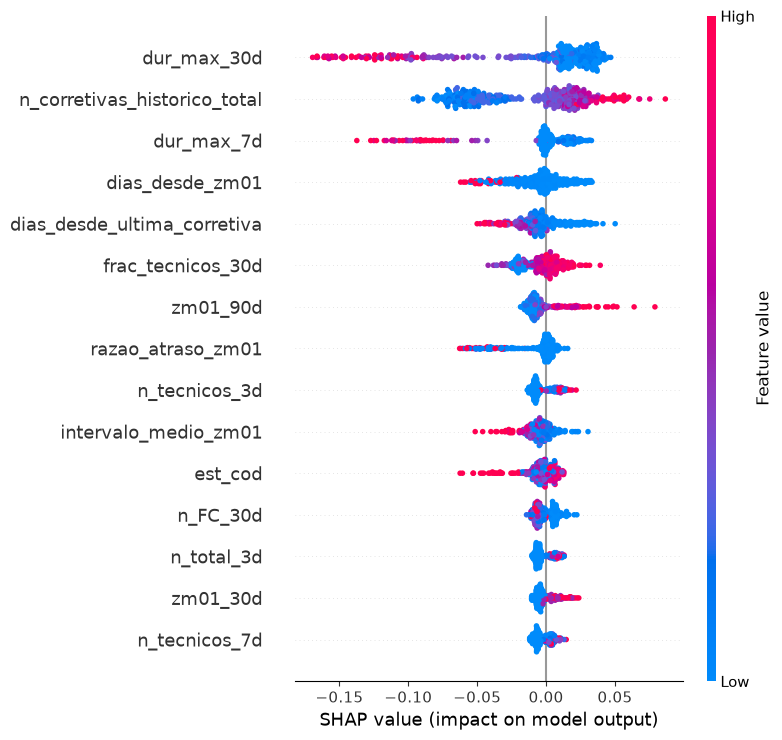

In [6]:
shap.summary_plot(sv[:, [FEATS.index(c) for c in imp.head(15)['feature']]],
                   amostra[imp.head(15)['feature']], show=True)

A importância acima descreve o candidato sem `num_porta`. Ela não demonstra, por si só, generalização para novos equipamentos.

## 6. Candidato reduzido por SHAP

Etapa exploratória adicional: selecionar atributos usando apenas o treino e avaliar um candidato reduzido. Não confundir o efeito dessa seleção com o efeito isolado de remover `num_porta`.

In [7]:
limiar_corte = imp['shap_abs_medio'].iloc[0] * 0.01
mantidas = imp[imp['shap_abs_medio'] >= limiar_corte]['feature'].tolist()
removidas = imp[imp['shap_abs_medio'] < limiar_corte]['feature'].tolist()
print(f'corte em {limiar_corte:.5f} (1% do shap da feature mais forte)')
print(f'mantidas: {len(mantidas)} | removidas: {len(removidas)}')
print('removidas:', removidas)
assert 'num_porta' not in mantidas
assert set(mantidas).issubset(FEATS)

corte em 0.00043 (1% do shap da feature mais forte)
mantidas: 70 | removidas: 12
removidas: ['zm02_30d', 'n_CSD_3d', 'n_FO_3d', 'n_RCE_7d', 'dia_semana', 'n_FO_1d', 'n_OA_1d', 'n_CSD_1d', 'n_CA_1d', 'fim_de_semana', 'n_RCE_3d', 'n_RCE_1d']


Os atributos removidos são listados pela execução acima; não se pressupõe uma quantidade ou melhora de desempenho.

In [8]:
mod_final, prob_final, lim_final, linha_final = treina_avalia(mantidas, '5.1 sem num_porta (seleção SHAP)')

R = pd.DataFrame([linha_controle, linha_full, linha_final])
print()
print(R.round(3).to_string(index=False))
assert 'num_porta' not in mod_final.feature_names_in_
R.to_csv(OUT / 'comparacao_modelos.csv', index=False)

[5.1 sem num_porta (seleção SHAP)] limiar=0.4684
                          modelo  precisao  recall    f1  pr_auc  roc_auc  alertas   tp    fp   fn  limiar  n_features
5.1 sem num_porta (seleção SHAP)     0.137   0.707 0.229   0.185    0.697    32092 4385 27707 1817   0.468          70

                            modelo  precisao  recall    f1  pr_auc  roc_auc  alertas   tp    fp   fn  limiar  n_features
            Controle com num_porta     0.161   0.533 0.247   0.185    0.696    20513 3303 17210 2899   0.526          83
5.1 sem num_porta (ablação direta)     0.156   0.572 0.245   0.184    0.696    22815 3550 19265 2652   0.517          82
  5.1 sem num_porta (seleção SHAP)     0.137   0.707 0.229   0.185    0.697    32092 4385 27707 1817   0.468          70


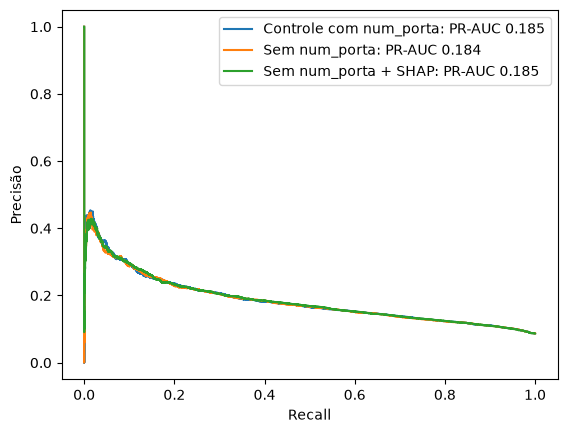

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

for nome, prob, linha in [
    ('Controle com num_porta', prob_controle, linha_controle),
    ('Sem num_porta', prob_full, linha_full),
    ('Sem num_porta + SHAP', prob_final, linha_final),
]:
    precision, recall, _ = precision_recall_curve(teste['y'], prob)
    plt.plot(recall, precision, label=f'{nome}: PR-AUC {linha["pr_auc"]:.3f}')
plt.xlabel('Recall'); plt.ylabel('Precisão'); plt.legend(); plt.show()

### Como interpretar os resultados

Compare primeiro controle e ablação direta, especialmente PR-AUC, precisão, recall e número de alertas. Cada limiar é ajustado por F1 apenas na validação; não é escolhido pelo teste.

As métricas por linha classificam se haverá uma corretiva nos próximos 1 a 7 dias, não o dia exato da falha. A etapa SHAP é uma segunda alteração e deve ser analisada separadamente.

Os resultados antigos não são reutilizados: ambos os modelos são retreinados sob o mesmo protocolo, inclusive com imputação fixa de 30 dias para intervalos sem histórico. Um único recorte temporal e uma semente não estabelecem significância estatística nem generalização para estações inéditas.

## 7. Hiperparâmetros fixos no experimento

A busca de hiperparâmetros fica fora desta ablação para não misturar seus efeitos com a remoção do identificador. Os três modelos usam 400 árvores, profundidade 14, mínimo de 40 amostras por folha, classes balanceadas e semente 42. Uma futura avaliação deve reservar estações/portas inteiras, preservando também a separação temporal.

## 8. Avaliação complementar por evento do candidato SHAP

Agrupamos dias consecutivos de alerta por porta e verificamos sua associação com corretivas futuras. Esta seção avalia apenas o candidato reduzido; a comparação controlada entre modelos está nas métricas por linha acima.

As janelas nas bordas do período podem ter observação parcial. A média harmônica abaixo combina recall por falha e precisão por episódio, unidades distintas; não é o F1 de uma única matriz de confusão.

In [10]:
# zm01 ja foi carregado na secao de features de ciclo -- reaproveita, nao recarrega
T = teste[['id_porta', 'Data', 'y']].copy()
T['prob'] = prob_final
T = T.sort_values(['id_porta', 'Data']).reset_index(drop=True)
T['alerta'] = (T['prob'] >= lim_final).astype(int)

INI_T, FIM_T = T['Data'].min(), T['Data'].max()
falhas_teste = zm01[(zm01['Data'] > INI_T) & (zm01['Data'] <= FIM_T + pd.Timedelta(days=7))][['id_porta', 'Data']] \
    .drop_duplicates()
falhas_teste = falhas_teste[falhas_teste['id_porta'].isin(T['id_porta'].unique())]
print(f'falhas reais (eventos) no periodo de teste: {len(falhas_teste)}')

falhas reais (eventos) no periodo de teste: 1178


In [11]:
def teve_alerta_antes(row):
    ip, d = row['id_porta'], row['Data']
    janela = T[(T['id_porta'] == ip) & (T['Data'] >= d - pd.Timedelta(days=7)) & (T['Data'] < d)]
    return int((janela['alerta'] == 1).any())


falhas_teste['detectada'] = falhas_teste.apply(teve_alerta_antes, axis=1)
recall_evento = falhas_teste['detectada'].mean()
print(f'recall por evento: {falhas_teste["detectada"].sum()}/{len(falhas_teste)} = {recall_evento*100:.1f}%')

recall por evento: 883/1178 = 75.0%


In [12]:
episodios = []
for ip, g in T.groupby('id_porta'):
    g = g.sort_values('Data').reset_index(drop=True)
    em_episodio = False
    for _, r in g.iterrows():
        if r['alerta'] == 1 and not em_episodio:
            em_episodio, inicio, fim_ep = True, r['Data'], r['Data']
        elif r['alerta'] == 1 and em_episodio:
            fim_ep = r['Data']
        elif r['alerta'] == 0 and em_episodio:
            episodios.append({'id_porta': ip, 'inicio': inicio, 'fim': fim_ep})
            em_episodio = False
    if em_episodio:
        episodios.append({'id_porta': ip, 'inicio': inicio, 'fim': fim_ep})

EP = pd.DataFrame(episodios, columns=['id_porta', 'inicio', 'fim'])
print(f'episodios de alerta (dias consecutivos agrupados): {len(EP)}  '
      f'(vs {T["alerta"].sum()} dias de alerta individuais)')


def houve_falha_no_range(row):
    hi = row['fim'] + pd.Timedelta(days=7)
    f = zm01[(zm01['id_porta'] == row['id_porta']) & (zm01['Data'] > row['inicio']) & (zm01['Data'] <= hi)]
    return int(len(f) > 0)


EP['acertou'] = EP.apply(houve_falha_no_range, axis=1) if not EP.empty else pd.Series(dtype=int)
precisao_evento = EP['acertou'].mean() if not EP.empty else 0.0
f1_evento = (2 * precisao_evento * recall_evento / (precisao_evento + recall_evento)
             if precisao_evento + recall_evento > 0 else 0.0)
print(f'precisao por episodio: {EP["acertou"].sum()}/{len(EP)} = {precisao_evento*100:.1f}%')
print(f'F1 por evento/episodio: {f1_evento:.3f}')

episodios de alerta (dias consecutivos agrupados): 1930  (vs 32092 dias de alerta individuais)
precisao por episodio: 528/1930 = 27.4%
F1 por evento/episodio: 0.401


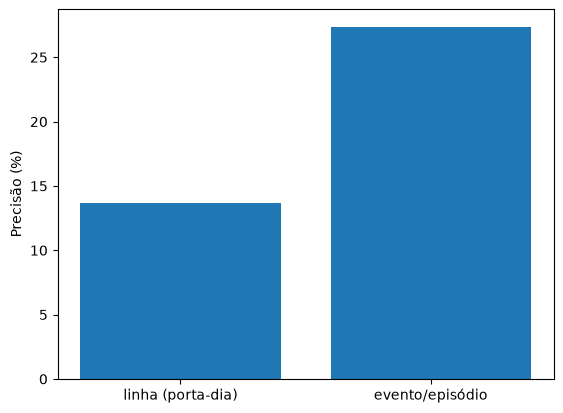

In [13]:
plt.bar(['linha (porta-dia)', 'evento/episódio'], [linha_final['precisao']*100, precisao_evento*100])
plt.ylabel('Precisão (%)'); plt.show()

Os valores exibidos são calculados nesta execução. Não reutilizar as conclusões ou percentuais do modelo anterior para este candidato.

## 9. Exportação isolada para teste

Salvamos o modelo da ablação direta e o candidato SHAP com listas explícitas de atributos. Não há publicação nem ativação no serviço de ML.

In [14]:
import json
import joblib

for nome, model, features, threshold in [
    ('modelo_5_1_sem_num_porta', mod_full, FEATS, lim_full),
    ('modelo_5_1_sem_num_porta_shap', mod_final, mantidas, lim_final),
]:
    assert 'num_porta' not in features
    assert list(model.feature_names_in_) == features
    joblib.dump({
        'model': model, 'features': features, 'threshold': float(threshold),
        'est_categorias': painel['est'].astype('category').cat.categories.tolist(),
        'version': nome, 'experimental': True,
    }, OUT / f'{nome}.joblib')

metadata = {
    'experiment': 'ablacao_num_porta', 'seed': 42,
    'excluded_feature': 'num_porta', 'retained_location_features': ['est_cod', 'via_cod'],
    'train_end': str(FIM_TREINO.date()), 'test_start': str(INI_TESTE.date()),
    'validation_start': str(INI_VALID.date()),
    'train_rows': len(treino), 'test_rows': len(teste),
    'features_control': FEATS_CONTROLE, 'features_ablation': FEATS,
    'features_shap': mantidas, 'metrics': R.to_dict(orient='records'),
    'generalization_to_unseen_doors_tested': False,
}
(OUT / 'experimento.json').write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False), encoding='utf-8')
print(f'Resultados experimentais salvos em {OUT}')

Resultados experimentais salvos em C:\Users\Inteli\Downloads\EC-M7\g04\models\modelo-5\artefatos\modelo_5_1


## 10. Conclusão a partir da execução

A remoção foi aplicada antes do treinamento: `num_porta` não pode entrar na seleção SHAP nem nos artefatos candidatos. Os identificadores continuam disponíveis para agrupar registros e avaliar eventos.

Use `comparacao_ablacao.csv` para avaliar o efeito isolado e `comparacao_modelos.csv` para incluir a seleção SHAP. Manter ou remover a variável deve considerar as métricas e o volume operacional de alertas, sem ajustar o experimento repetidamente ao teste final.

Este experimento não testa portas/estações inéditas e não remove todas as formas indiretas de identificação. Não conclua que a memorização foi eliminada apenas pela retirada de `num_porta`.